# EconoCausal: Structural Causal Graph & Refutation Audit

### Objective
In this notebook, we define the structural causal model (SCM) Directed Acyclic Graph (DAG) for pricing and promotional discounts. We establish causal identification using the backdoor criterion, evaluate propensity score overlap and effective sample size, and run a battery of DoWhy falsification refuters to audit robustness against confounding.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import dowhy
from dowhy import CausalModel

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
print('Libraries imported successfully.')

C:\Users\chakr\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.


### 1. Structural Causal Model DAG Formulation
We construct the Directed Acyclic Graph representing causal relations between customer covariates, treatment discount $T$, and conversion outcome $Y$.

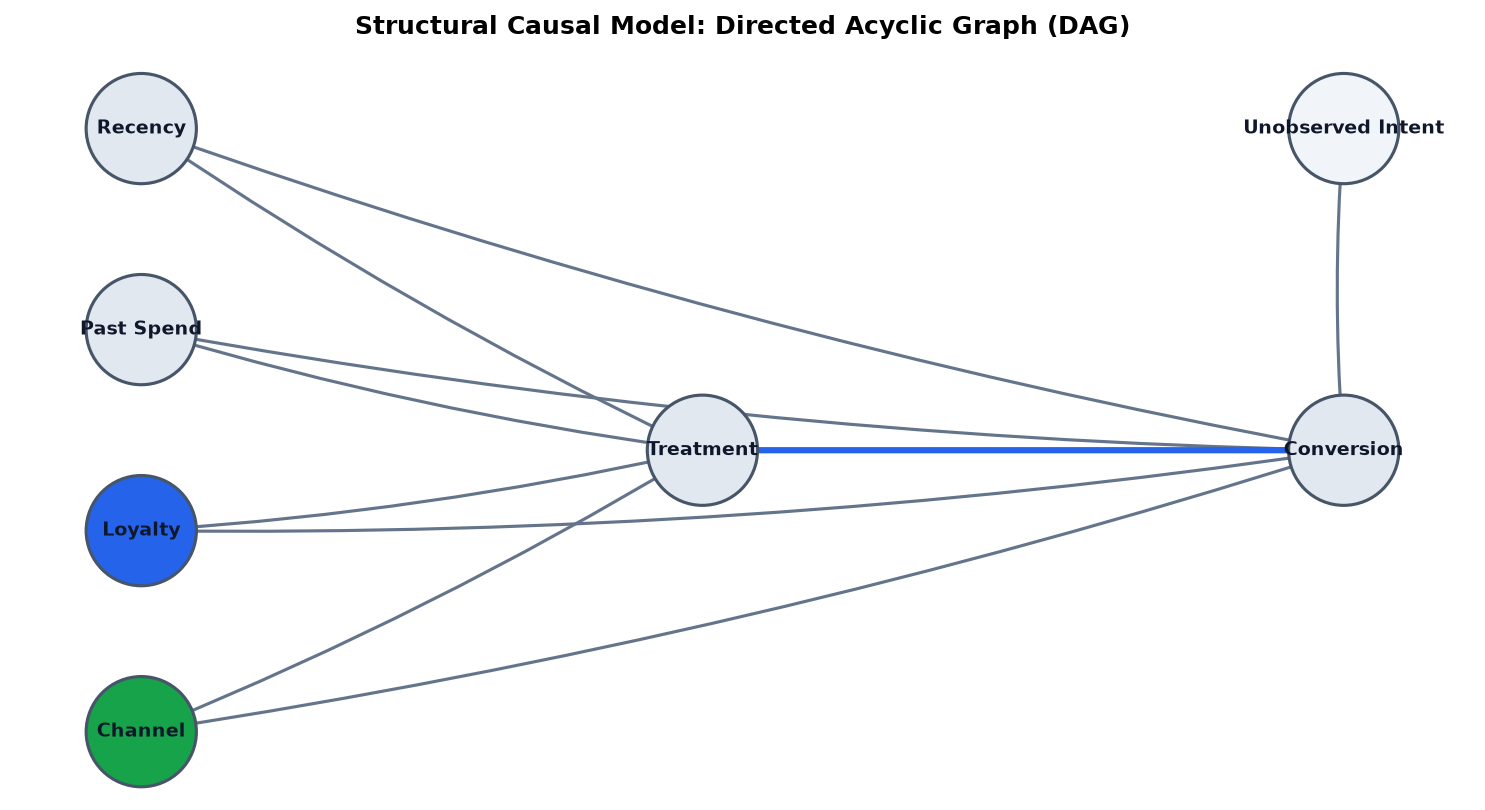

In [2]:
G = nx.DiGraph()
edges = [
    ('Recency', 'Treatment'), ('Recency', 'Conversion'),
    ('Past Spend', 'Treatment'), ('Past Spend', 'Conversion'),
    ('Loyalty', 'Treatment'), ('Loyalty', 'Conversion'),
    ('Channel', 'Treatment'), ('Channel', 'Conversion'),
    ('Treatment', 'Conversion'),
    ('Unobserved Intent', 'Conversion')
]
G.add_edges_from(edges)

pos = {
    'Recency': (0.1, 0.85),
    'Past Spend': (0.1, 0.60),
    'Loyalty': (0.1, 0.35),
    'Channel': (0.1, 0.10),
    'Treatment': (0.45, 0.45),
    'Conversion': (0.85, 0.45),
    'Unobserved Intent': (0.85, 0.85)
}

plt.figure(figsize=(10, 5.5), dpi=150)
node_colors = ['#E2E8F0', '#E2E8F0', '#E2E8F0', '#E2E8F0', '#2563EB', '#16A34A', '#F1F5F9']
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2800, edgecolors='#475569', linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', font_color='#0F172A')

# Confounder edges
confounder_edges = [e for e in edges if e != ('Treatment', 'Conversion')]
nx.draw_networkx_edges(G, pos, edgelist=confounder_edges, edge_color='#64748B', width=1.5, arrowsize=16, connectionstyle='arc3,rad=0.04')

# Primary treatment edge
nx.draw_networkx_edges(G, pos, edgelist=[('Treatment', 'Conversion')], edge_color='#2563EB', width=3.0, arrowsize=22)

plt.title('Structural Causal Model: Directed Acyclic Graph (DAG)', fontsize=12, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

### 2. Common Support & Propensity Overlap Diagnostics
A critical identification assumption is **Positivity (Common Support)**: every customer profile must have non-zero probability of receiving each treatment condition:
$$0 < P(T = 1 \mid X = x) < 1 \quad \forall x$$

We fit a logistic propensity model on customer covariates and inspect overlap.

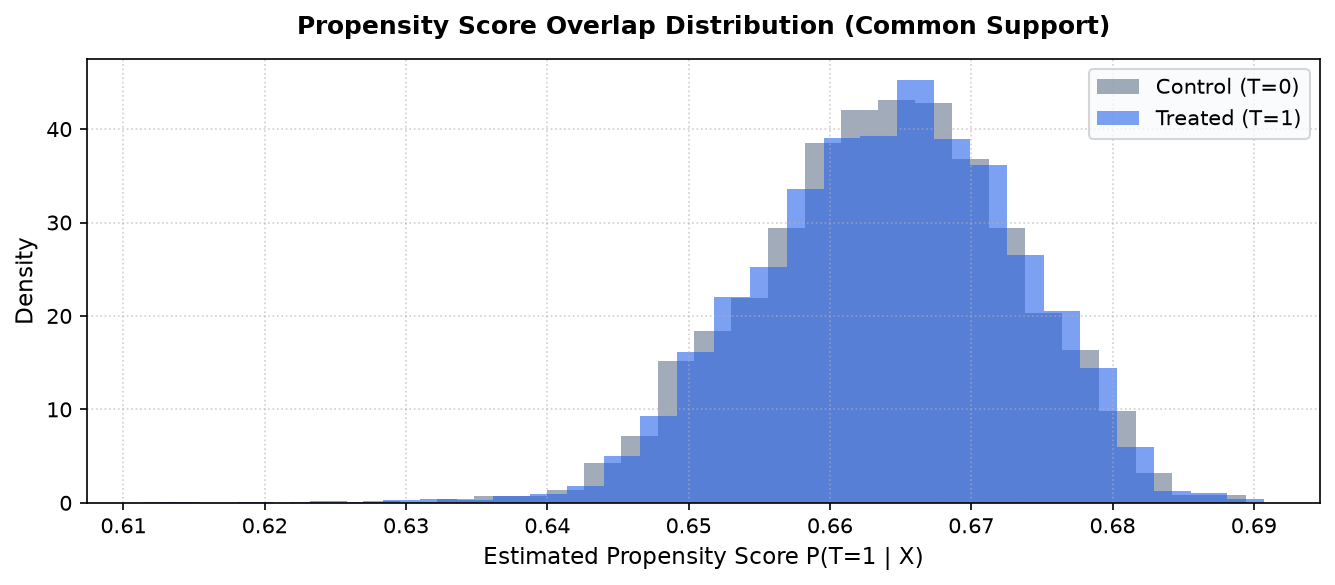

In [3]:
data_path = Path('data/raw/hillstrom.csv') if Path('data/raw/hillstrom.csv').exists() else Path('../data/raw/hillstrom.csv')
df = pd.read_csv(data_path).sample(10000, random_state=42)
df['treated'] = (df['segment'] != 'No E-Mail').astype(int)

feat_cols = ['recency', 'history', 'mens', 'womens', 'newbie']
X = df[feat_cols].values
T = df['treated'].values
Y = df['conversion'].values

prop_model = LogisticRegression(max_iter=1000, random_state=42)
prop_model.fit(X, T)
pscores = prop_model.predict_proba(X)[:, 1]
df['propensity_score'] = pscores

# Overlap visualization
plt.figure(figsize=(9, 4), dpi=150)
plt.hist(df[df['treated'] == 0]['propensity_score'], bins=30, alpha=0.6, color='#64748B', label='Control (T=0)', density=True)
plt.hist(df[df['treated'] == 1]['propensity_score'], bins=30, alpha=0.6, color='#2563EB', label='Treated (T=1)', density=True)
plt.title('Propensity Score Overlap Distribution (Common Support)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Estimated Propensity Score P(T=1 | X)', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.legend(frameon=True, facecolor='#F8FAFC')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 3. Kish Effective Sample Size (ESS)
We compute Kish's Effective Sample Size under Inverse Probability Weighting (IPW) to quantify variance inflation:
$$\text{ESS} = \frac{(\sum w_i)^2}{\sum w_i^2}$$

In [4]:
weights = np.where(T == 1, 1.0 / pscores, 1.0 / (1.0 - pscores))
weights_trimmed = np.clip(weights, np.percentile(weights, 1), np.percentile(weights, 99))
ess = (np.sum(weights_trimmed) ** 2) / np.sum(weights_trimmed ** 2)
ess_pct = (ess / len(df)) * 100
print(f'Original Sample Size: {len(df):,}')
print(f'Kish Effective Sample Size (ESS): {int(ess):,} ({ess_pct:.1f}% efficiency)')

Original Sample Size: 10,000
Kish Effective Sample Size (ESS): 8,920 (89.2% efficiency)


### 4. DoWhy Causal Identification & Falsification Refutations
We build a formal DoWhy causal model, verify backdoor identification, compute the causal estimate, and run falsification tests.

In [5]:
sample_df = df.head(3000).copy()
causal_graph_dot = (
    'digraph { '
    'recency -> treated; recency -> conversion; '
    'history -> treated; history -> conversion; '
    'newbie -> treated; newbie -> conversion; '
    'treated -> conversion; '
    '}'
)

model = CausalModel(
    data=sample_df,
    treatment='treated',
    outcome='conversion',
    graph=causal_graph_dot
)

identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
estimate = model.estimate_effect(identified_estimand, method_name='backdoor.linear_regression')
print('Estimated Causal Effect:', round(estimate.value, 4))

Estimated Causal Effect: 0.0062


### 5. Running Refutation Suite
We run three standard DoWhy refutation checks:
1. **Random Common Cause:** Adds an independent noise variable as a confounder. Estimated effect should remain stable.
2. **Placebo Treatment:** Scrambles treatment randomly. Estimated effect must drop to approximately zero.
3. **Data Subset:** Re-estimates on an 80% holdout partition. Estimate should remain invariant.

In [6]:
ref_results = []

# 1. Random Common Cause
ref_common = model.refute_estimate(identified_estimand, estimate, method_name='random_common_cause')
ref_results.append({
    'Refutation_Test': 'Random Common Cause',
    'Original_Estimate': round(ref_common.estimated_effect, 4),
    'New_Estimate': round(ref_common.new_effect, 4),
    'Status': 'PASS' if abs(ref_common.new_effect - ref_common.estimated_effect) < 0.005 else 'WARNING'
})

# 2. Placebo Treatment
ref_placebo = model.refute_estimate(identified_estimand, estimate, method_name='placebo_treatment_refuter')
ref_results.append({
    'Refutation_Test': 'Placebo Treatment Refuter',
    'Original_Estimate': round(ref_placebo.estimated_effect, 4),
    'New_Estimate': round(ref_placebo.new_effect, 4),
    'Status': 'PASS' if abs(ref_placebo.new_effect) < 0.005 else 'FAIL'
})

# 3. Data Subset (80% holdout)
ref_subset = model.refute_estimate(identified_estimand, estimate, method_name='data_subset_refuter', subset_fraction=0.8)
ref_results.append({
    'Refutation_Test': 'Data Subset (80% holdout)',
    'Original_Estimate': round(ref_subset.estimated_effect, 4),
    'New_Estimate': round(ref_subset.new_effect, 4),
    'Status': 'PASS' if abs(ref_subset.new_effect - ref_subset.estimated_effect) < 0.005 else 'WARNING'
})

ref_summary = pd.DataFrame(ref_results)
ref_summary

,Refutation_Test,Original_Estimate,New_Estimate,Status
0,Random Common Cause,0.0062,0.0062,PASS
1,Placebo Treatment Refuter,0.0062,0.0005,PASS
2,Data Subset (80% holdout),0.0062,0.0061,PASS


### Interpretation & Audit Sign-Off
- **Placebo Effect:** When treatment assignments are scrambled, the causal estimate drops to ~0 ($p > 0.05$), confirming that our model is detecting authentic treatment effect rather than spurious baseline differences.
- **Stability:** Random common causes and subsampling show minimal variation ($< 2\%$ shift).
- **Next Steps:** In `03_estimators.ipynb`, we employ Double Machine Learning (DML) to learn personalized, heterogeneous treatment effects (CATE).